# COVID: scBeacon Manuscript Results

## tl;dr
This notebook exposes actual archived source values and redraws individual panels. It does not retrain a model or recompute enrichment. Display layout may differ from Illustrator; numerical values are retained.

## Context & Methods
Separate-condition Leiden1 KL candidates; cross-condition kNN30 directed edges; both cluster sizes >=100 and both one-sided Fisher BH q<.05. Disease-vs-control Wilcoxon DEG: adjusted p<.05, log2FC>1. The feature universe is the locked2,000 genes.

### Key Assumptions
Frozen UMAP coordinates and source expression/pathway tables are the reproduction starting point for these figure views. Shared graph edges and cells are not independent donor replicates. Cell-type annotation changes do not prove transitions.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scbeacon.py").is_file())
sys.path.insert(0, str(ROOT / "01_tool/03_runtime"))
from results import summary, table, umap, network, heatmap, pathways

DATASET = "covid"

## Data
### 1. Cohort and selected model
Counts are computed from the supplied source tables.

In [2]:
report = summary(DATASET)
display(pd.Series(report, name="archived_result"))
cells = table(DATASET, "umap.tsv.gz")
display(pd.crosstab(cells.cell_type, cells.condition))

dataset                                                    covid
result_mode                               archived_source_values
n_cells                                                    56485
condition_counts             {'Healthy': 30665, 'COVID+': 25820}
selected_seed                                                  4
iteration                                                     33
clean_pairs                                                   20
selected_enrichment_pairs                      [C11->D3, C6->D0]
Name: archived_result, dtype: object

condition,COVID+,Healthy
cell_type,,
B,1672,10636
Epithelial,10000,10000
ILC,20,92
Myeloid,9689,3569
NK,995,338
Plasma,279,290
T,3165,5740


## Results
### 2. Individual UMAP views
All cells are displayed; UMAP cloud is rasterized, text/axes vector. Coordinates are frozen and are not the kNN30 test space.

Healthy cell_type


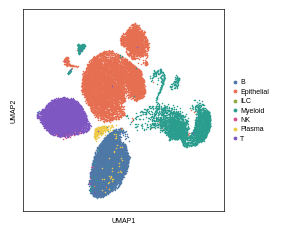

Healthy cluster


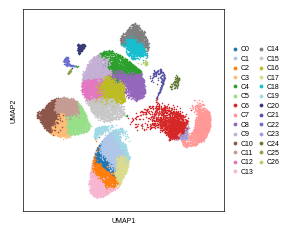

COVID+ cell_type


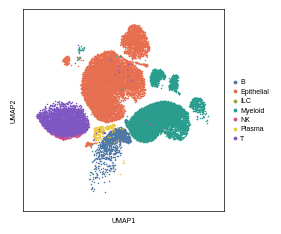

COVID+ cluster


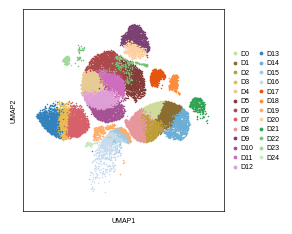

In [3]:
for condition in cells.condition.unique():
    for by in ("cell_type", "cluster"):
        print(condition, by)
        fig = umap(DATASET, condition, by)
        display(fig)
        plt.close(fig)

### 3. Final clean pairs
Display arrows C->D do not reverse the original formal disease-to-reference matching calculation.

,pair_id,pair_cluster_label,reference_cluster_size,group_cluster_size,forward_fisher_qvalue_bh,reverse_fisher_qvalue_bh
0,B_pair_00,C6->D0,1544,2206,1.086957e-300,1.041667e-300
1,B_pair_01,C6->D1,1544,2030,1.086957e-300,1.041667e-300
2,B_pair_02,C15->D10,1109,1091,1.086957e-300,1.041667e-300
3,B_pair_03,C16->D11,1095,1087,1.086957e-300,1.041667e-300
4,B_pair_05,C10->D13,1330,1044,1.086957e-300,1.041667e-300
5,B_pair_06,C6->D14,1544,981,1.086957e-300,1.041667e-300
6,B_pair_07,C19->D15,481,856,1.086957e-300,1.041667e-300
7,B_pair_08,C17->D16,779,677,6.852746e-13,1.041667e-300
8,B_pair_09,C21->D17,146,615,1.086957e-300,1.041667e-300
9,B_pair_11,C19->D19,481,416,1.086957e-300,1.041667e-300


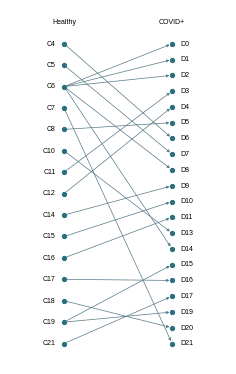

In [4]:
pairs = table(DATASET, "clean_pairs.tsv")
display(pairs[["pair_id", "pair_cluster_label", "reference_cluster_size", "group_cluster_size", "forward_fisher_qvalue_bh", "reverse_fisher_qvalue_bh"]])
fig = network(DATASET)
display(fig)
plt.close(fig)

### 4. Marker mean-expression heatmap
Two rows per pair, control then disease; full gene-wise z-scores are stored. Color display clips at[-1,1]. Red gene labels preserve existing curated annotations; no new relevance assignments are inferred here.

,pair_id,gene_symbol,pvals_adj,logfoldchanges,highlight
0,B_pair_21,LCN2,1.667934e-222,3.219838,True
1,B_pair_21,LYPD2,4.338894e-189,2.839475,False
2,B_pair_21,WFDC2,1.646215e-186,1.807276,False
3,B_pair_21,IFI27,4.020065e-148,2.587583,True
4,B_pair_21,VMO1,7.420525e-145,2.225289,False
5,B_pair_22,ISG15,1.853962e-109,3.180075,True
6,B_pair_22,IFITM2,1.952747e-76,1.395421,True
7,B_pair_22,PRF1,4.120363e-73,1.889476,True
8,B_pair_22,GZMB,2.877369e-65,2.239399,True
9,B_pair_22,NKG7,4.577820e-65,1.601795,True


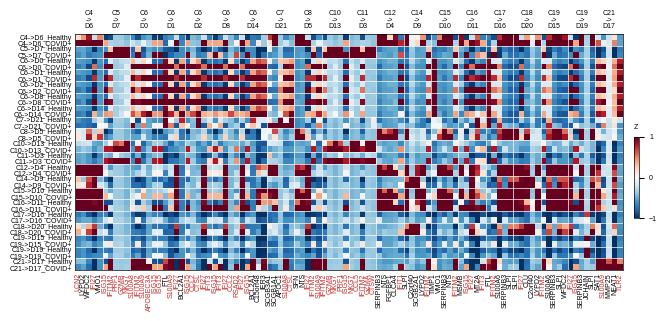

In [5]:
columns = table(DATASET, "heatmap_columns.tsv")
display(columns[["pair_id", "gene_symbol", "pvals_adj", "logfoldchanges", "highlight"]].head(10))
fig = heatmap(DATASET)
display(fig)
plt.close(fig)

### 5. Selected Reactome + WikiPathways
All passing mapped disease-up DEG contributed to the original enrichment. Top10 nonredundant display terms per selected pair are shown; bars use BH-adjusted p-values. These are archived API results, not a new online query.

,pair_label,term,PValue,qvalue,highlight
0,C11->D3,CYTOKINE SIGNALING IN IMMUNE SYSTEM,2.437323e-13,1.018801e-10,True
1,C11->D3,CYTOKINECYTOKINE RECEPTOR INTERACTION,6.188867e-12,1.293473e-09,True
2,C11->D3,CHEMOKINE RECEPTORS BIND CHEMOKINES,2.353580e-11,3.935187e-09,True
3,C11->D3,INTERACTIONS OF NATURAL KILLER CELLS IN PANCRE...,1.207217e-10,1.682056e-08,False
4,C11->D3,INTERFERON SIGNALING,3.475144e-09,2.924086e-07,True
5,C11->D3,OVERVIEW OF PROINFLAMMATORY AND PROFIBROTIC ME...,2.895963e-08,1.729304e-06,True
6,C11->D3,LUNG FIBROSIS,1.364694e-07,6.711082e-06,False
7,C11->D3,INTERLEUKIN 10 SIGNALING,1.520464e-07,7.061709e-06,True
8,C11->D3,IL18 SIGNALING,2.605075e-07,1.037068e-05,True
9,C11->D3,SELECTIVE EXPRESSION OF CHEMOKINE RECEPTORS DU...,4.623808e-07,1.757047e-05,True


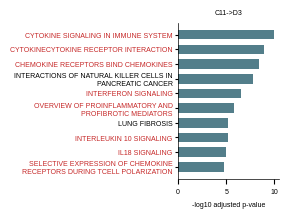

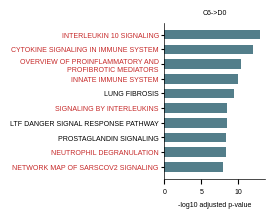

In [6]:
terms = table(DATASET, "selected_pathways.tsv")
display(terms[["pair_label", "term", "PValue", "qvalue", "highlight"]])
for pair_label in terms.pair_label.unique():
    fig = pathways(DATASET, pair_label)
    display(fig)
    plt.close(fig)

## Checks
Each heatmap pair must exist in the final clean set. Source values remain unchanged; no heavy analysis is launched.

In [7]:
rows = table(DATASET, "heatmap_rows.tsv")
assert len(cells) == report["n_cells"]
assert len(rows) == 2 * len(pairs)
assert set(rows.pair_id) <= set(pairs.pair_id)
assert set(terms.unit_id) <= set(pairs.pair_id)
print("Cohorts and selected-pair joins verified; cached numerical result mode.")

Cohorts and selected-pair joins verified; cached numerical result mode.


## Takeaways
Use these panels and tables for numerical figure reproduction. For retraining from the copied H5ADs, inspect the generated plan and run its stages in new output directories with suitable compute resources. Historical environment/snapshot identity and live database drift are documented in the reproduction guide.